# Credit card default: neural network on all features

A logistic regression plus a hidden layer of logistic regressions, joined by a skip connection,

$$h_j = \sigma(v_j^\top x + c_j), \qquad p = \sigma(x^\top \beta + h^\top w + b),$$

on **all 68 features** (the logistic regression in `logistic_regression.ipynb` uses 18 of them, chosen by forward selection): the 44 original candidates, 10 behaviour features and 14 features made for tree models, all from `eda.ipynb`. Training uses:
- **AdamW**: Adam with weight decay applied directly to the hidden weights $V$ and $w$.
- **Cosine learning-rate schedule**: the step size falls smoothly from $\eta_0$ to 0.
- **Dropout**: each hidden unit is switched off at random during training.
- **Tuned hidden-layer size**, plus an ensemble of 5 networks with different seeds.

Everything is tuned by 5-fold cross-validation on the development set; the test set is used once at the end.

In [1]:
import os
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # silence CMU font-weight warnings

CURATED = '../data/curated/credit_default.csv'
PLOTS = '../plots/neural_network'
os.makedirs(PLOTS, exist_ok=True)
MONTHS = ['sep', 'aug', 'jul', 'jun', 'may', 'apr']

plt.style.use(['science', 'no-latex', 'grid'])
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.family': 'sans-serif', 'font.sans-serif': ['CMU Sans Serif'],
    'mathtext.fontset': 'custom', 'mathtext.rm': 'CMU Sans Serif',
    'mathtext.it': 'CMU Sans Serif:italic', 'mathtext.bf': 'CMU Sans Serif:bold',
    'axes.unicode_minus': False, 'axes.formatter.use_mathtext': False,  # CMU has no Unicode minus glyph
})

## Data
Same split and folds as the other notebooks.

In [2]:
if not os.path.exists(CURATED):  # data/ is not in the repo: build it with the EDA notebook
    subprocess.run([sys.executable, '-m', 'nbconvert', '--to', 'notebook', '--execute', '--inplace', 'eda.ipynb'], check=True)
df = pd.read_csv(CURATED)
y = df['default'].values

rng = np.random.default_rng(42)
test_ids = rng.choice(np.arange(1, 30001), size=6000, replace=False)
is_test = df['id'].isin(test_ids).values
test_idx = np.flatnonzero(is_test)

dev_idx = np.flatnonzero(~is_test)
rng.shuffle(dev_idx)
folds = np.array_split(dev_idx, 5)
len(dev_idx), len(test_idx), [len(f) for f in folds]

(23995, 5999, [4799, 4799, 4799, 4799, 4799])

## Features
All 68 candidates from `logistic_regression.ipynb`: the original features and interaction terms, the 10 behaviour features (payment ratios, trends, `max_late`, ...) and the 14 features made for tree models. They are standardized with the mean and SD of the clients the model is fit on.

In [3]:
candidates = (['log_credit_limit', 'age'] + [f'late_{m}' for m in MONTHS]
              + ['late_sep_m2', 'late_sep_m1', 'late_sep_1', 'late_sep_2', 'late_sep_3plus']
              + [f'log_bill_{m}' for m in MONTHS] + [f'log_paid_{m}' for m in MONTHS]
              + [f'util_{m}' for m in MONTHS] + ['months_late', 'credit_balance_months']
              + ['late_x_util', 'late_x_limit', 'months_late_x_util', 'age_x_limit', 'late_sep_x_aug']
              + ['female', 'edu_university', 'edu_high_school', 'edu_other', 'single', 'marital_other'])
candidates += ([f'pay_ratio_{m}' for m in MONTHS[:-1]]
               + ['util_trend', 'late_trend', 'zero_pay_months', 'max_late', 'months_since_late']
               + [f'unpaid_{m}' for m in MONTHS[:-1]]
               + ['log_available_credit', 'util_mean', 'util_max', 'util_std', 'total_pay_ratio',
                  'late_streak', 'months_late_2plus', 'bill_change_sep', 'bill_change_aug'])

def standardize(idx, ref):
    A = df[candidates].values
    mu, sd = A[ref].mean(axis=0), A[ref].std(axis=0)
    return (A[idx] - mu) / sd

def fit_and_hold(k):
    """Indices to fit on (4 folds) and to hold out (fold k)."""
    return np.concatenate(folds[:k] + folds[k + 1:]), folds[k]

len(candidates)

68

## Logistic regression
The starting point for the network and the baseline it has to beat, fitted on the same 68 features.

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_likelihood(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

def fit_logistic(X, y, lr=0.5, n_iter=3000):
    beta, b = np.zeros(X.shape[1]), np.zeros(1)
    for _ in range(n_iter):
        e = y - sigmoid(X @ beta + b)
        beta += lr * X.T @ e / len(y)
        b += lr * e.mean()
    return beta, b

## The network
**Dropout.** During training, each hidden unit is kept with probability $1 - q$ and otherwise set to 0. The kept units are scaled by $1/(1-q)$, so at prediction time (no dropout) the output has the same expected size. It stops the network relying on any one hidden unit. With $k_{ij}$ the scaled 0/1 mask and $a_{ij} = k_{ij} h_{ij}$:

$$p_i = \sigma(x_i^\top \beta + a_i^\top w + b)$$

**Gradients of the average log-likelihood**, with $e_i = y_i - p_i$:

$$\frac{\partial \ell}{\partial \beta} = \frac{1}{n}\sum_i e_i x_i, \qquad \frac{\partial \ell}{\partial w} = \frac{1}{n}\sum_i e_i a_i, \qquad \frac{\partial \ell}{\partial v_j} = \frac{1}{n}\sum_i \underbrace{e_i\, w_j\, k_{ij}\, h_{ij}(1 - h_{ij})}_{\delta_{ij}} x_i$$

The weight decay is not part of the gradient: AdamW applies it as a separate step (below).

**Start.** $\beta, b$ from the fitted logistic regression, $V$ random with SD $1/\sqrt{d}$, and $w$ random with SD 0.01. That is close to the logistic regression but not exactly equal, so the hidden units start learning straight away.

In [5]:
def init_network(beta, b, H, seed):
    rng = np.random.default_rng(seed)
    d = len(beta)
    return {'V': rng.normal(0, 1 / np.sqrt(d), (H, d)), 'c': np.zeros(H), 'w': rng.normal(0, 0.01, H),
            'beta': beta.copy(), 'b': b.copy()}

def forward(net, X, keep=None):
    """keep: dropout mask (n x H), 0 or 1/(1-q). None at prediction time."""
    h = sigmoid(X @ net['V'].T + net['c'])
    a = h if keep is None else h * keep
    p = sigmoid(X @ net['beta'] + a @ net['w'] + net['b'])
    return h, a, p

def gradients(net, X, y, keep=None):
    h, a, p = forward(net, X, keep)
    e = y - p
    n = len(y)
    delta = e[:, None] * net['w'] * (1 if keep is None else keep) * h * (1 - h)
    return {'V': delta.T @ X / n, 'c': delta.mean(axis=0), 'w': a.T @ e / n,
            'beta': X.T @ e / n, 'b': np.array([e.mean()])}

## Gradient check
Compare the backpropagation formulas with numerical derivatives on 200 clients, with a fixed dropout mask so the dropout path is checked too. Relative errors around $10^{-7}$ or smaller mean the formulas are right.

In [6]:
def avg_ll(net, X, y, keep):
    return log_likelihood(forward(net, X, keep)[2], y) / len(y)

check_rng = np.random.default_rng(1)
X_check, y_check = standardize(dev_idx[:200], dev_idx), y[dev_idx[:200]]
net = init_network(check_rng.normal(0, 0.1, len(candidates)), np.array([-1.0]), 8, seed=1)
net['w'] = check_rng.normal(0, 1, 8)
keep = (check_rng.random((200, 8)) >= 0.2) / 0.8

analytic = gradients(net, X_check, y_check, keep)
for k, v in net.items():
    numeric = np.zeros_like(v)
    for i in np.ndindex(v.shape):
        old = v[i]
        v[i] = old + 1e-6
        up = avg_ll(net, X_check, y_check, keep)
        v[i] = old - 1e-6
        down = avg_ll(net, X_check, y_check, keep)
        v[i] = old
        numeric[i] = (up - down) / 2e-6
    rel = np.max(np.abs(analytic[k] - numeric)) / np.max(np.abs(analytic[k]) + np.abs(numeric))
    print(f'{k:5s} relative error {rel:.1e}')

V     relative error 1.3e-09
c     relative error 1.4e-09
w     relative error 4.4e-10
beta  relative error 3.9e-10
b     relative error 1.4e-10


## Training: AdamW, cosine schedule, mini-batches
- **Mini-batches** of 512 clients, reshuffled every epoch.
- **Adam** keeps running averages of each parameter's gradient $m$ and squared gradient $s$ and moves it by $\eta_t\, \hat m / (\sqrt{\hat s} + \epsilon)$, so every parameter moves at a similar rate.
- **AdamW weight decay.** After each Adam step, the hidden weights shrink by $\eta_t \lambda$: $\;V \leftarrow V - \eta_t \lambda V$, $\;w \leftarrow w - \eta_t \lambda w$. In plain Adam an L2 penalty is rescaled along with the gradient, which can make even small penalties switch the hidden layer off entirely. Applying it directly keeps the strength of the decay the same for every weight.
- **Cosine schedule.** Over the full budget of `EPOCHS` epochs the step size falls as $\eta_t = \tfrac{1}{2}\eta_0\big(1 + \cos(\pi t / T)\big)$: large steps early to make progress, small steps late to settle.

With held-out data, the average log-likelihood on the training and held-out clients is recorded after every epoch (entry 0 is before training). The schedule always assumes the full budget, so a model stopped early at epoch $k$ has had exactly the same updates as epoch $k$ of the tuning run.

In [7]:
EPOCHS, BATCH, LR0 = 120, 512, 0.002

def learning_rate(t, total):
    return 0.5 * LR0 * (1 + np.cos(np.pi * t / total))

def train(X, y, init, H, wd, dropout, seed=0, stop=EPOCHS, X_hold=None, y_hold=None):
    rng = np.random.default_rng(seed)
    net = init_network(*init, H, seed)
    m = {k: np.zeros_like(v) for k, v in net.items()}
    s = {k: np.zeros_like(v) for k, v in net.items()}
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    total = EPOCHS * int(np.ceil(len(y) / BATCH))
    t = 0
    hold_curve, fit_curve = [], []
    for epoch in range(stop + 1):
        if X_hold is not None:
            hold_curve.append(log_likelihood(forward(net, X_hold)[2], y_hold))
            fit_curve.append(log_likelihood(forward(net, X)[2], y) / len(y))
        if epoch == stop:
            break
        order = rng.permutation(len(y))
        for start in range(0, len(y), BATCH):
            i = order[start:start + BATCH]
            keep = None if dropout == 0 else (rng.random((len(i), H)) >= dropout) / (1 - dropout)
            g = gradients(net, X[i], y[i], keep)
            lr = learning_rate(t, total)
            t += 1
            for k in net:
                m[k] = beta1 * m[k] + (1 - beta1) * g[k]
                s[k] = beta2 * s[k] + (1 - beta2) * g[k]**2
                net[k] += lr * (m[k] / (1 - beta1**t)) / (np.sqrt(s[k] / (1 - beta2**t)) + eps)
                if k in ('V', 'w'):
                    net[k] -= lr * wd * net[k]
    return net, np.array(hold_curve), np.array(fit_curve)

def predict(net, X):
    return forward(net, X)[2]

## Cross-validation
Each fold's standardized data and logistic regression start are computed once and reused for every configuration. `cv_curves` trains one configuration on all 5 folds and returns, for every epoch, the cross-validated average log-likelihood (held out) and the average training log-likelihood.

Results are cached in `data/cache/`, so if the run is interrupted, re-running skips finished configurations. Progress is also appended to `data/cache/nn_progress.log`.

In [8]:
import json
import time

CACHE_DIR = '../data/cache'
CACHE = f'{CACHE_DIR}/nn_tuning.json'
LOG = f'{CACHE_DIR}/nn_progress.log'
os.makedirs(CACHE_DIR, exist_ok=True)
cache = json.load(open(CACHE)) if os.path.exists(CACHE) else {}

def log(msg):
    print(msg)
    with open(LOG, 'a') as f:
        f.write(f'{time.strftime("%H:%M:%S")} {msg}\n')

fold_data = []
for k in range(len(folds)):
    fit_idx, hold = fit_and_hold(k)
    X_fit, X_hold = standardize(fit_idx, fit_idx), standardize(hold, fit_idx)
    fold_data.append((X_fit, y[fit_idx], X_hold, y[hold], fit_logistic(X_fit, y[fit_idx])))

lr_all_cv = sum(log_likelihood(sigmoid(Xh @ init[0] + init[1]), yh) for _, _, Xh, yh, init in fold_data) / len(dev_idx)
log(f'logistic regression, all features, cross-validated: {lr_all_cv:.4f}')

def cv_curves(H, wd, dropout):
    key = f'{len(candidates)} features, {EPOCHS} epochs: H={H} wd={wd:g} dropout={dropout:g}'
    if key not in cache:
        start = time.time()
        hold_total, fit_total = 0, 0
        for X_fit, y_fit, X_hold, y_hold, init in fold_data:
            _, hold_curve, fit_curve = train(X_fit, y_fit, init, H, wd, dropout, X_hold=X_hold, y_hold=y_hold)
            hold_total = hold_total + hold_curve
            fit_total = fit_total + fit_curve / len(fold_data)
        cache[key] = {'hold': list(hold_total / len(dev_idx)), 'fit': list(fit_total)}
        json.dump(cache, open(CACHE, 'w'))
        best = np.max(cache[key]['hold'])
        log(f'{key:28s} best {best:.4f} at epoch {np.argmax(cache[key]["hold"])} ({time.time() - start:.0f}s)')
    return np.array(cache[key]['hold']), np.array(cache[key]['fit'])

logistic regression, all features, cross-validated: -0.4299


## Stage 1: hidden-layer size
Moderate weight decay (λ = 0.1), no dropout. The best epoch of each curve is what early stopping would pick.

In [9]:
HIDDEN = [8, 16, 32, 64, 128]
stage1 = {H: cv_curves(H, 0.1, 0)[0] for H in HIDDEN}
best_H = max(HIDDEN, key=lambda H: stage1[H].max())
log(f'best hidden-layer size: {best_H}')

best hidden-layer size: 64


## Stage 2: weight decay and dropout
For the best hidden-layer size.

In [10]:
WDS, DROPOUTS = [0, 0.01, 0.1, 1.0], [0, 0.2]
stage2 = {(wd, q): cv_curves(best_H, wd, q)[0] for wd in WDS for q in DROPOUTS}
best_wd, best_q = max(stage2, key=lambda key: stage2[key].max())
best_epoch = int(stage2[(best_wd, best_q)].argmax())
log(f'chosen: H={best_H}, weight decay {best_wd:g}, dropout {best_q:g}, {best_epoch} epochs')

chosen: H=64, weight decay 0.1, dropout 0.2, 110 epochs


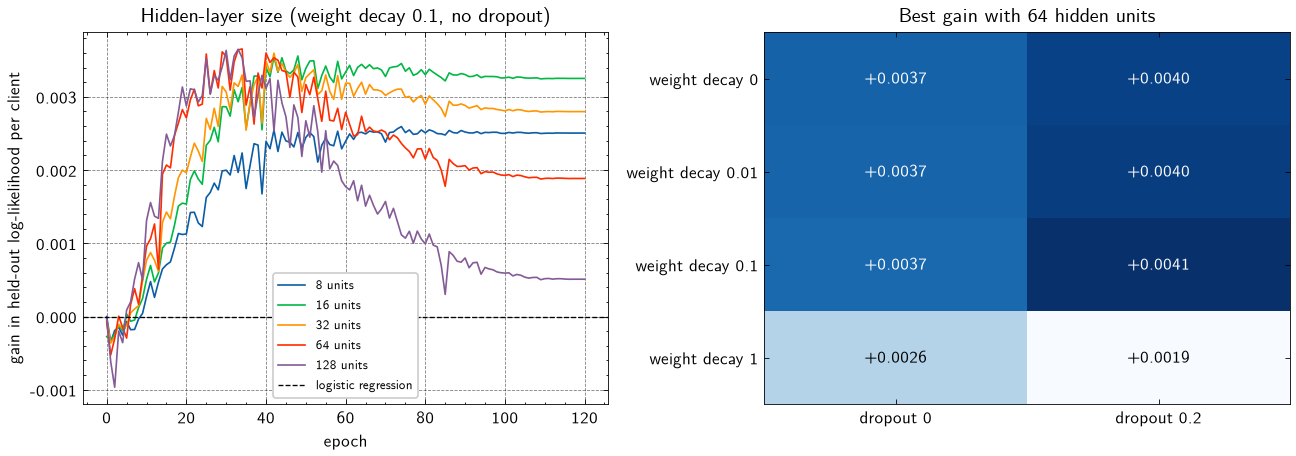

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
epochs = np.arange(EPOCHS + 1)
for H in HIDDEN:
    ax.plot(epochs, stage1[H] - lr_all_cv, label=f'{H} units')
ax.axhline(0, color='k', linestyle='--', linewidth=0.8, label='logistic regression')
ax.set_xlabel('epoch')
ax.set_ylabel('gain in held-out log-likelihood per client')
ax.set_title('Hidden-layer size (weight decay 0.1, no dropout)')
ax.legend(fontsize=8)

ax = axes[1]
grid = np.array([[stage2[(wd, q)].max() - lr_all_cv for q in DROPOUTS] for wd in WDS])
im = ax.imshow(grid, cmap='Blues', aspect='auto')
for i in range(len(WDS)):
    for j in range(len(DROPOUTS)):
        ax.text(j, i, f'{grid[i, j]:+.4f}', ha='center', va='center',
                color='white' if grid[i, j] > grid.min() + 0.6 * (grid.max() - grid.min()) else 'black')
ax.set_xticks(range(len(DROPOUTS)), [f'dropout {q:g}' for q in DROPOUTS])
ax.set_yticks(range(len(WDS)), [f'weight decay {wd:g}' for wd in WDS])
ax.grid(False)
ax.minorticks_off()
ax.set_title(f'Best gain with {best_H} hidden units')
plt.tight_layout()
plt.savefig(f'{PLOTS}/tuning.png')
plt.show()

## Training curves of the chosen configuration
Left: the cosine learning-rate schedule. Right: average log-likelihood on the training and held-out clients. The gap between them is overfitting, and the grey line is where early stopping stops.

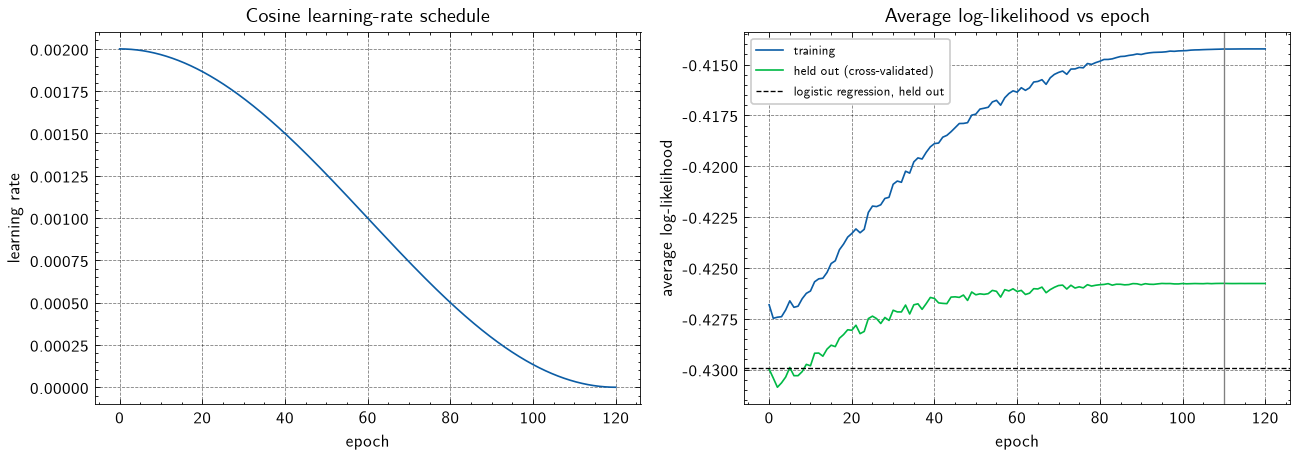

In [12]:
hold_curve, fit_curve = cv_curves(best_H, best_wd, best_q)
steps = EPOCHS * int(np.ceil(len(fold_data[0][1]) / BATCH))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(np.arange(steps) / (steps / EPOCHS), [learning_rate(t, steps) for t in range(steps)])
ax.set_xlabel('epoch')
ax.set_ylabel('learning rate')
ax.set_title('Cosine learning-rate schedule')

ax = axes[1]
ax.plot(epochs, fit_curve, label='training')
ax.plot(epochs, hold_curve, label='held out (cross-validated)')
ax.axhline(lr_all_cv, color='k', linestyle='--', linewidth=0.8, label='logistic regression, held out')
ax.axvline(best_epoch, color='grey', linewidth=0.8)
ax.set_xlabel('epoch')
ax.set_ylabel('average log-likelihood')
ax.set_title('Average log-likelihood vs epoch')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{PLOTS}/training.png')
plt.show()

## Ensemble and threshold
Train 5 networks with the chosen settings and different seeds, stopped at the chosen epoch, and average their probabilities. The threshold catches 65% of defaulters on the out-of-fold ensemble predictions. The two logistic regressions get their thresholds the same way.

In [13]:
SEEDS = range(5)
SELECTED = ['months_since_late', 'late_sep_1', 'months_late_2plus', 'log_credit_limit', 'late_sep_2', 'log_paid_sep',
            'log_paid_jul', 'log_available_credit', 'log_paid_jun', 'edu_other', 'single', 'late_sep_m1', 'unpaid_aug',
            'log_bill_sep', 'months_late_x_util', 'late_sep_3plus', 'late_sep', 'util_jul']
sel = [candidates.index(c) for c in SELECTED]

oof = {name: np.full(len(df), np.nan) for name in ['logistic selected', 'logistic all', 'network all']}
for k, (X_fit, y_fit, X_hold, y_hold, init) in enumerate(fold_data):
    hold = folds[k]
    oof['logistic all'][hold] = sigmoid(X_hold @ init[0] + init[1])
    beta13, b13 = fit_logistic(X_fit[:, sel], y_fit)
    oof['logistic selected'][hold] = sigmoid(X_hold[:, sel] @ beta13 + b13)
    oof['network all'][hold] = np.mean([predict(train(X_fit, y_fit, init, best_H, best_wd, best_q, seed, stop=best_epoch)[0], X_hold)
                                       for seed in SEEDS], axis=0)
    log(f'out-of-fold ensemble: fold {k + 1} done')

thresholds = np.arange(0.05, 0.9, 0.01)
y_dev = y[dev_idx]

def pick_threshold(p):
    recall = [np.sum((p >= t) & (y_dev == 1)) / y_dev.sum() for t in thresholds]
    return thresholds[np.array(recall) >= 0.65].max()

threshold = {name: round(float(pick_threshold(p[dev_idx])), 2) for name, p in oof.items()}
threshold

out-of-fold ensemble: fold 1 done


out-of-fold ensemble: fold 2 done


out-of-fold ensemble: fold 3 done


out-of-fold ensemble: fold 4 done


out-of-fold ensemble: fold 5 done


{'logistic selected': 0.2, 'logistic all': 0.2, 'network all': 0.21}

## Final models and test results
Refit everything on all 24,000 development clients and score the test set once.

In [14]:
def confusion(y, pred):
    tp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    tn = np.sum((pred == 0) & (y == 0))
    return tp, fp, fn, tn

def roc(y, proba):
    y_sorted = y[np.argsort(-proba)]
    tpr = np.concatenate([[0], np.cumsum(y_sorted) / y.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y_sorted) / (1 - y).sum()])
    return fpr, tpr, np.trapezoid(tpr, fpr)

In [15]:
X_dev, X_test = standardize(dev_idx, dev_idx), standardize(test_idx, dev_idx)
y_test = y[test_idx]
init_dev = fit_logistic(X_dev, y_dev)
beta13, b13 = fit_logistic(X_dev[:, sel], y_dev)

proba = {'logistic selected': sigmoid(X_test[:, sel] @ beta13 + b13),
         'logistic all': sigmoid(X_test @ init_dev[0] + init_dev[1])}
proba['network all'] = np.mean([predict(train(X_dev, y_dev, init_dev, best_H, best_wd, best_q, seed, stop=best_epoch)[0], X_test)
                               for seed in SEEDS], axis=0)
log('final ensemble trained')

boot = np.random.default_rng(0)
resamples = [boot.integers(0, len(y_test), len(y_test)) for _ in range(2000)]
boot_auc = {name: np.array([roc(y_test[i], p[i])[2] for i in resamples]) for name, p in proba.items()}

rows = []
for name, p in proba.items():
    tp, fp, fn, tn = confusion(y_test, (p >= threshold[name]).astype(int))
    rows.append({'model': name, 'test AUC': round(roc(y_test, p)[2], 3), 'AUC std. error': round(boot_auc[name].std(), 4),
                 'accuracy at 0.5': round(np.mean((p >= 0.5) == y_test), 3), 'threshold': round(threshold[name], 2),
                 'defaulters caught': tp, 'false alarms': fp})
results = pd.DataFrame(rows).set_index('model')
log('\n' + results.to_string())

for name in proba:
    if name != 'network all':
        gain = boot_auc['network all'] - boot_auc[name]
        log(f'AUC gain of network all over {name}: {roc(y_test, proba["network all"])[2] - roc(y_test, proba[name])[2]:+.4f}, '
            f'95% interval {np.percentile(gain, 2.5):+.4f} to {np.percentile(gain, 97.5):+.4f}')
results

final ensemble trained



                   test AUC  AUC std. error  accuracy at 0.5  threshold  defaulters caught  false alarms
model                                                                                                   
logistic selected     0.782          0.0074            0.820       0.20                864          1053
logistic all          0.778          0.0075            0.821       0.20                864          1095
network all           0.785          0.0073            0.821       0.21                859          1058
AUC gain of network all over logistic selected: +0.0028, 95% interval -0.0014 to +0.0074
AUC gain of network all over logistic all: +0.0063, 95% interval +0.0027 to +0.0101


,test AUC,AUC std. error,accuracy at 0.5,threshold,defaulters caught,false alarms
model,,,,,,
logistic selected,0.782,0.0074,0.820,0.20,864,1053
logistic all,0.778,0.0075,0.821,0.20,864,1095
network all,0.785,0.0073,0.821,0.21,859,1058


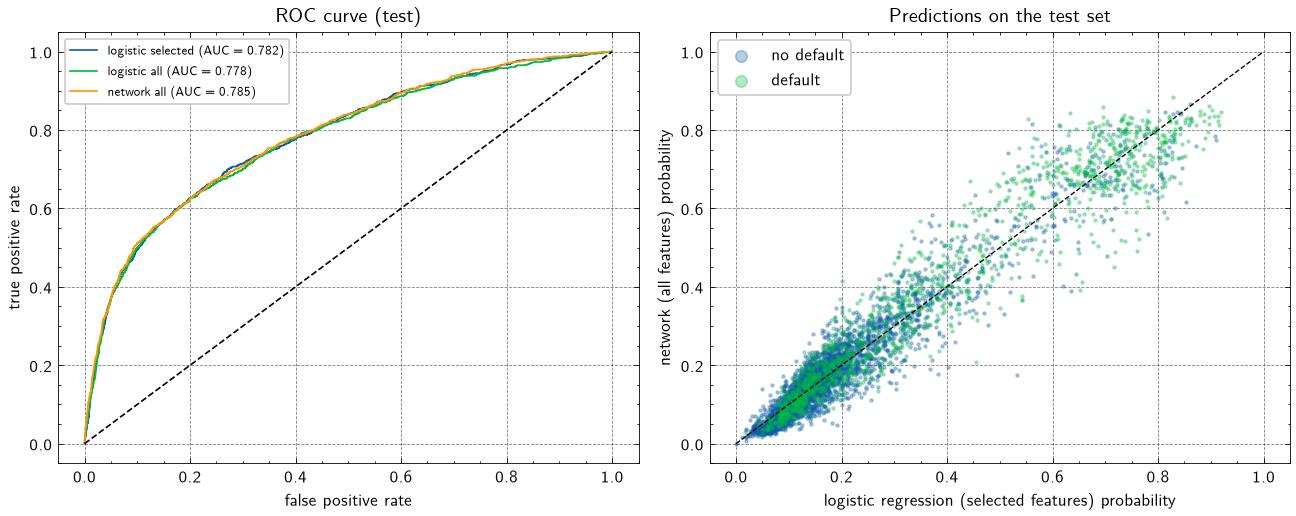

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
for name, p in proba.items():
    fpr, tpr, a = roc(y_test, p)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {a:.3f})')
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate')
ax.set_title('ROC curve (test)')
ax.legend(fontsize=8)

ax = axes[1]
p_lr, p_nn = proba['logistic selected'], proba['network all']
ax.scatter(p_lr[y_test == 0], p_nn[y_test == 0], s=3, alpha=0.3, label='no default')
ax.scatter(p_lr[y_test == 1], p_nn[y_test == 1], s=3, alpha=0.3, label='default')
ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
ax.set_xlabel('logistic regression (selected features) probability')
ax.set_ylabel('network (all features) probability')
ax.set_title('Predictions on the test set')
ax.legend(markerscale=4)
plt.tight_layout()
plt.savefig(f'{PLOTS}/roc.png')
plt.show()

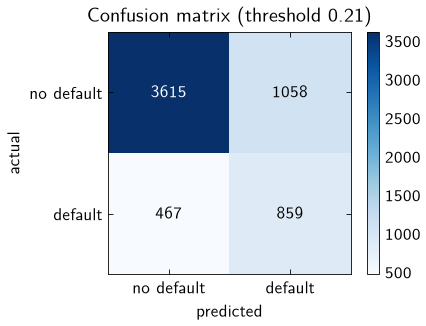

In [17]:
p, t = proba['network all'], threshold['network all']
tp, fp, fn, tn = confusion(y_test, (p >= t).astype(int))
cm = np.array([[tn, fp], [fn, tp]])
labels = ['no default', 'default']

plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xticks([0, 1], labels)
plt.yticks([0, 1], labels)
plt.grid(False)
plt.minorticks_off()
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title(f'Confusion matrix (threshold {t:.2f})')
plt.colorbar()
plt.savefig(f'{PLOTS}/confusion_matrix.png')
plt.show()

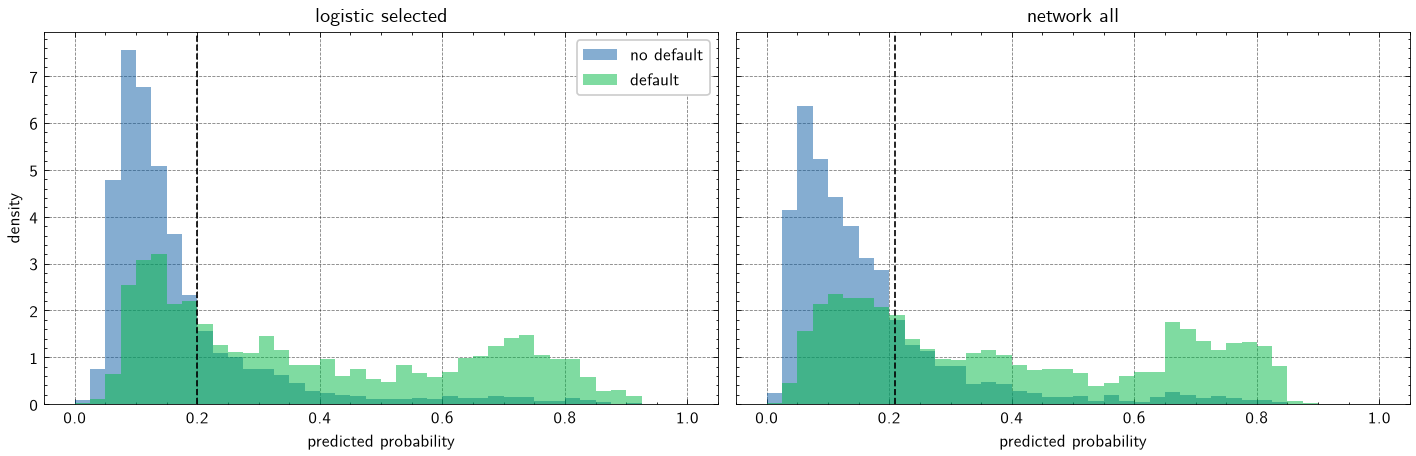

In [18]:
bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ['logistic selected', 'network all']):
    ax.hist(proba[name][y_test == 0], bins=bins, alpha=0.5, density=True, label='no default')
    ax.hist(proba[name][y_test == 1], bins=bins, alpha=0.5, density=True, label='default')
    ax.axvline(threshold[name], color='k', linestyle='--')
    ax.set_xlabel('predicted probability')
    ax.set_title(name)
axes[0].set_ylabel('density')
axes[0].legend()
plt.tight_layout()
plt.savefig(f'{PLOTS}/probability_distribution.png')
plt.show()

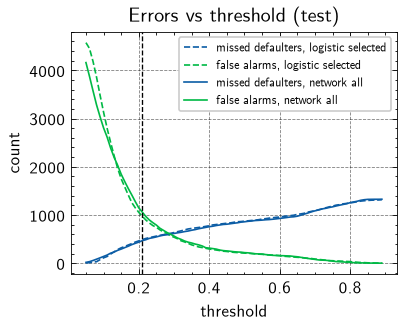

In [19]:
grid_t = np.arange(0.05, 0.9, 0.01)
for name, style in [('logistic selected', '--'), ('network all', '-')]:
    errs = np.array([confusion(y_test, (proba[name] >= t).astype(int)) for t in grid_t])
    plt.plot(grid_t, errs[:, 2], 'C0' + style, label=f'missed defaulters, {name}')
    plt.plot(grid_t, errs[:, 1], 'C1' + style, label=f'false alarms, {name}')
plt.axvline(threshold['network all'], color='k', linestyle='--', linewidth=0.8)
plt.xlabel('threshold')
plt.ylabel('count')
plt.title('Errors vs threshold (test)')
plt.legend(fontsize=7)
plt.savefig(f'{PLOTS}/errors_vs_threshold.png')
plt.show()